# Lab 3 Homework solutions

## Setup

In [1]:
import os

import matplotlib.pyplot as plt
import polars as pl

DATA_DIR = "data"
if not os.path.exists(DATA_DIR):
    os.mkdir(DATA_DIR)


total_size = sum(
    os.path.getsize(f"{DATA_DIR}/{month}.parquet") for month in range(1, 13)
)  # bytes
total_size_mb = total_size // (1024 * 1024)
print(f"Total dataset size: {total_size_mb} MB")


Total dataset size: 660 MB


## 1. Data reading

In [2]:
dfs_lazy = []
for month in range(1, 13):
    df = pl.scan_parquet(f"{DATA_DIR}/{month}.parquet")
    df = df.with_columns(
        pl.col("tpep_pickup_datetime").dt.cast_time_unit("ms"),
        pl.col("tpep_dropoff_datetime").dt.cast_time_unit("ms"),
    )
    dfs_lazy.append(df)
df_2024_lazy: pl.LazyFrame = pl.concat(dfs_lazy)

df_taxi_zones = pl.scan_csv(f"{DATA_DIR}/taxi_zone_lookup.csv")

display(df_2024_lazy.describe())
display(df_taxi_zones.describe())

statistic,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
str,f64,str,str,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",4.116972e7,"""41169720""","""41169720""",3.7078488e7,4.116972e7,3.7078488e7,"""37078488""",4.116972e7,4.116972e7,4.116972e7,4.116972e7,4.116972e7,4.116972e7,4.116972e7,4.116972e7,4.116972e7,4.116972e7,3.7078488e7,3.7078488e7
"""null_count""",0.0,"""0""","""0""",4.091232e6,0.0,4.091232e6,"""4091232""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.091232e6,4.091232e6
"""mean""",1.764232,"""2024-07-06 10:01:25.051000""","""2024-07-06 10:18:53.125000""",1.333931,4.976101,2.32215,null,164.242786,163.447453,1.107259,19.26851,1.385953,0.479777,3.307884,0.561527,0.962993,27.832813,2.232144,0.147006
"""std""",0.425857,null,null,0.815824,419.230497,10.928049,null,64.340689,69.60009,0.651511,76.71984,1.815878,0.130183,4.090523,2.240545,0.255055,78.053586,0.874653,0.502041
"""min""",1.0,"""2002-12-31 16:46:07""","""2002-12-31 17:24:07""",0.0,0.0,1.0,"""N""",1.0,1.0,0.0,-2261.2,-9.25,-0.5,-300.0,-140.63,-1.0,-2265.45,-2.5,-1.75
"""25%""",2.0,"""2024-04-06 20:07:28""","""2024-04-06 20:23:52""",1.0,1.01,1.0,null,132.0,113.0,1.0,9.3,0.0,0.5,0.0,0.0,1.0,15.75,2.5,0.0
"""50%""",2.0,"""2024-07-03 23:35:16""","""2024-07-03 23:50:35""",1.0,1.76,1.0,null,161.0,162.0,1.0,13.5,1.0,0.5,2.6,0.0,1.0,21.0,2.5,0.0
"""75%""",2.0,"""2024-10-08 17:33:35""","""2024-10-08 17:53:27""",1.0,3.36,1.0,null,233.0,234.0,1.0,22.6,2.5,0.5,4.25,0.0,1.0,30.6,2.5,0.0
"""max""",7.0,"""2026-06-26 23:53:12""","""2026-06-27 20:59:10""",9.0,398608.62,99.0,"""Y""",265.0,265.0,5.0,335544.44,65.99,41.3,999.99,1702.88,2.0,335550.94,2.52,1.75


statistic,LocationID,Borough,Zone,service_zone
str,f64,str,str,str
"""count""",265.0,"""265""","""265""","""265"""
"""null_count""",0.0,"""0""","""0""","""0"""
"""mean""",133.0,null,null,null
"""std""",76.643112,null,null,null
"""min""",1.0,"""Bronx""","""Allerton/Pelham Gardens""","""Airports"""
"""25%""",67.0,null,null,null
"""50%""",133.0,null,null,null
"""75%""",199.0,null,null,null
"""max""",265.0,"""Unknown""","""Yorkville West""","""Yellow Zone"""


In [3]:
df_2024 = df_2024_lazy.filter(
    pl.col("tpep_pickup_datetime").is_between(
        pl.datetime(2024, 1, 1), pl.datetime(2025, 1, 1), closed="left"
    ),
    pl.col("tpep_dropoff_datetime").is_between(
        pl.datetime(2024, 1, 1), pl.datetime(2025, 1, 1), closed="both"
    ),
)

display(
    df_2024.select(
        pl.col("tpep_pickup_datetime").min().alias("min_pickup"),
        pl.col("tpep_pickup_datetime").max().alias("max_pickup"),
        pl.col("tpep_dropoff_datetime").min().alias("min_dropoff"),
        pl.col("tpep_dropoff_datetime").max().alias("max_dropoff"),
    ).collect()
)


min_pickup,max_pickup,min_dropoff,max_dropoff
datetime[ms],datetime[ms],datetime[ms],datetime[ms]
2024-01-01 00:00:00,2024-12-31 23:59:21,2024-01-01 00:02:42,2025-01-01 00:00:00


In [4]:
display(df_2024.collect_schema())

Schema([('VendorID', Int32),
        ('tpep_pickup_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('tpep_dropoff_datetime', Datetime(time_unit='ms', time_zone=None)),
        ('passenger_count', Int64),
        ('trip_distance', Float64),
        ('RatecodeID', Int64),
        ('store_and_fwd_flag', String),
        ('PULocationID', Int32),
        ('DOLocationID', Int32),
        ('payment_type', Int64),
        ('fare_amount', Float64),
        ('extra', Float64),
        ('mta_tax', Float64),
        ('tip_amount', Float64),
        ('tolls_amount', Float64),
        ('improvement_surcharge', Float64),
        ('total_amount', Float64),
        ('congestion_surcharge', Float64),
        ('Airport_fee', Float64)])

In [5]:
display(df_2024.select(pl.col("store_and_fwd_flag")).unique().collect())

store_and_fwd_flag
str
null
"""N"""
"""Y"""


In [6]:
display(df_2024.select(pl.col("payment_type")).unique().sort("payment_type").collect())

payment_type
i64
0
1
2
3
4
5


In [7]:
df_2024 = df_2024.with_columns(
    pl.col("passenger_count").cast(pl.Int8),
    pl.col("store_and_fwd_flag").cast(pl.Enum(["Y", "N"])),
    pl.col("payment_type").cast(pl.Int8)
)

In [8]:
display(df_taxi_zones.collect_schema())

Schema([('LocationID', Int64),
        ('Borough', String),
        ('Zone', String),
        ('service_zone', String)])

In [9]:
df_taxi_zones = df_taxi_zones.with_columns(
    pl.col("LocationID").cast(pl.Int16),
    pl.col("Borough").cast(pl.Categorical),
    pl.col("Zone").cast(pl.Categorical),
    pl.col("service_zone").cast(pl.Categorical)
)

display(df_taxi_zones.describe())

statistic,LocationID,Borough,Zone,service_zone
str,f64,str,str,str
"""count""",265.0,"""265""","""265""","""265"""
"""null_count""",0.0,"""0""","""0""","""0"""
"""mean""",133.0,null,null,null
"""std""",76.643112,null,null,null
"""min""",1.0,null,null,null
"""25%""",67.0,null,null,null
"""50%""",133.0,null,null,null
"""75%""",199.0,null,null,null
"""max""",265.0,null,null,null


## 2. Data cleaning

In [10]:
df_2024 = (
    df_2024
    .with_columns(
        pl.col("passenger_count").fill_null(1).clip(upper_bound=6),
    )
    .filter(
        pl.col("passenger_count") > 0,
        pl.col("tpep_dropoff_datetime") - pl.col("tpep_pickup_datetime") <= pl.duration(hours=2)
    )
)

display(df_2024.describe())


statistic,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
str,f64,str,str,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",4.0726051e7,"""40726051""","""40726051""",4.0726051e7,4.0726051e7,3.663525e7,"""36635250""",4.0726051e7,4.0726051e7,4.0726051e7,4.0726051e7,4.0726051e7,4.0726051e7,4.0726051e7,4.0726051e7,4.0726051e7,4.0726051e7,3.663525e7,3.663525e7
"""null_count""",0.0,"""0""","""0""",0.0,0.0,4.090801e6,"""4090801""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.090801e6,4.090801e6
"""mean""",1.771771,"""2024-07-06 12:54:35.873000""","""2024-07-06 13:11:19.686000""",1.313314,4.987061,2.291145,null,164.225143,163.395328,1.105799,19.254399,1.368395,0.47967,3.310356,0.561147,0.962971,27.821567,2.2322,0.147498
"""std""",0.421079,null,null,0.772984,421.223804,10.791962,null,64.333498,69.589021,0.652632,76.63715,1.808708,0.130419,4.084256,2.235353,0.255676,77.97095,0.875695,0.502917
"""min""",1.0,"""2024-01-01 00:00:00""","""2024-01-01 00:02:42""",1.0,0.0,1.0,null,1.0,1.0,0.0,-999.0,-9.25,-0.5,-300.0,-117.26,-1.0,-1000.0,-2.5,-1.75
"""25%""",2.0,"""2024-04-06 21:56:31""","""2024-04-06 22:11:30""",1.0,1.01,1.0,null,132.0,113.0,1.0,9.3,0.0,0.5,0.0,0.0,1.0,15.75,2.5,0.0
"""50%""",2.0,"""2024-07-04 13:33:25""","""2024-07-04 13:46:34""",1.0,1.76,1.0,null,161.0,162.0,1.0,13.5,1.0,0.5,2.6,0.0,1.0,21.0,2.5,0.0
"""75%""",2.0,"""2024-10-08 19:28:22""","""2024-10-08 19:45:12""",1.0,3.36,1.0,null,233.0,234.0,1.0,22.6,2.5,0.5,4.25,0.0,1.0,30.6,2.5,0.0
"""max""",7.0,"""2024-12-31 23:59:21""","""2025-01-01 00:00:00""",6.0,398608.62,99.0,null,265.0,265.0,5.0,335544.44,65.99,35.84,999.99,1702.88,2.0,335550.94,2.52,1.75


In [11]:
money_cols = [
    "fare_amount",
    "extra",
    "mta_tax",
    "tip_amount",
    "tolls_amount",
    "improvement_surcharge",
    "total_amount",
    "congestion_surcharge",
    "Airport_fee",
]

df_2024 = (
    df_2024
    .with_columns(
    pl.col(money_cols).abs()
    )
    .filter(
        pl.all_horizontal(pl.col(money_cols) <= 1_000)
    )
)

display(df_2024.describe())


statistic,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee
str,f64,str,str,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",3.663524e7,"""36635240""","""36635240""",3.663524e7,3.663524e7,3.663524e7,"""36635240""",3.663524e7,3.663524e7,3.663524e7,3.663524e7,3.663524e7,3.663524e7,3.663524e7,3.663524e7,3.663524e7,3.663524e7,3.663524e7,3.663524e7
"""null_count""",0.0,"""0""","""0""",0.0,0.0,0.0,"""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",1.769662,"""2024-07-05 17:21:35.332000""","""2024-07-05 17:38:15.162000""",1.348299,3.500945,2.291142,null,164.974233,164.290251,1.229276,19.91372,1.547183,0.493484,3.59593,0.619832,0.992087,29.083002,2.299823,0.156961
"""std""",0.421273,null,null,0.807489,85.85863,10.791952,null,63.332207,69.341318,0.567187,18.834764,1.815949,0.057168,4.140512,2.283016,0.088494,23.510029,0.678506,0.500045
"""min""",1.0,"""2024-01-01 00:00:00""","""2024-01-01 00:02:42""",1.0,0.0,1.0,null,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""25%""",2.0,"""2024-04-05 15:17:29""","""2024-04-05 15:37:34""",1.0,1.0,1.0,null,132.0,114.0,1.0,9.3,0.0,0.5,1.0,0.0,1.0,15.96,2.5,0.0
"""50%""",2.0,"""2024-07-03 16:10:12""","""2024-07-03 16:28:34""",1.0,1.7,1.0,null,162.0,162.0,1.0,13.5,1.0,0.5,2.86,0.0,1.0,21.0,2.5,0.0
"""75%""",2.0,"""2024-10-08 19:41:43""","""2024-10-08 19:57:57""",1.0,3.27,1.0,null,233.0,234.0,1.0,21.9,2.5,0.5,4.45,0.0,1.0,30.94,2.5,0.0
"""max""",7.0,"""2024-12-31 23:59:21""","""2025-01-01 00:00:00""",6.0,160244.91,99.0,null,265.0,265.0,5.0,999.0,16.19,35.84,747.47,528.56,1.0,1000.0,2.52,1.75


In [12]:
df_2024 = df_2024.filter(
    pl.col("RatecodeID").is_in([1, 2, 3, 4, 5, 6, 99]),
    pl.col("VendorID").is_in([1, 2, 6, 7]),
)

# Sanity check, nulls and outside dict values removed

display(
    df_2024.select(
        pl.col("RatecodeID").unique().sort().alias("unique_ratecode_ids"),
    ).collect()
)

display(
    df_2024.select(
        pl.col("VendorID").unique().sort().alias("unique_vendor_ids"),
    ).collect()
)

display(df_2024.select(pl.col(["RatecodeID", "VendorID"]).null_count()).collect())


unique_ratecode_ids
i64
1
2
3
4
5
6
99


unique_vendor_ids
i32
1
2
7


RatecodeID,VendorID
u32,u32
0,0


## 3. Data transformation

In [13]:
payment_mapping = {
    0: "Other",
    1: "Credit card",
    2: "Cash",
    3: "Other",
    4: "Other",
    5: "Other",
    6: "Other",
}

df_2024 = df_2024.with_columns(
    pl.col("payment_type")
    .replace_strict(payment_mapping, default="Other")
    .cast(pl.String)
    .cast(pl.Categorical)
)

display(df_2024.select(pl.col("payment_type").value_counts(sort=True)).collect())


payment_type
struct[2]
"{""Credit card"",30100169}"
"{""Cash"",5461980}"
"{""Other"",1073091}"


In [14]:
df_2024 = (
    df_2024.join(
        df_taxi_zones.select(
            pl.col("LocationID").cast(pl.Int64).alias("PULocationID"),
            pl.col("Borough").alias("pickup_borough"),
        ),
        on="PULocationID",
        how="left",
    )
    .join(
        df_taxi_zones.select(
            pl.col("LocationID").cast(pl.Int64).alias("DOLocationID"),
            pl.col("Borough").alias("dropoff_borough"),
        ),
        on="DOLocationID",
        how="left",
    )
    .drop("PULocationID", "DOLocationID")
    .with_columns(pl.col("pickup_borough", "dropoff_borough").fill_null("Unknown"))
)

In [15]:
pickup_time = pl.col("tpep_pickup_datetime").dt.time()
df_2024 = df_2024.with_columns(
    (pl.col("Airport_fee") != 0).fill_null(False).alias("is_airport_ride"),
    (
        (pl.col("tpep_pickup_datetime").dt.weekday() <= 5)
        & (
            pickup_time.is_between(pl.time(6, 30), pl.time(9, 30))
            | pickup_time.is_between(pl.time(15, 30), pl.time(20, 0))
        )
    )
    .fill_null(False)
    .alias("is_rush_hour"),
)

## 4. Feature extraction and export

In [ ]:
boroughs = (
    df_taxi_zones.select(pl.col("Borough").cast(pl.String))
    .unique()
    .collect()["Borough"]
    .drop_nulls()
    .to_list()
)
boroughs = sorted(set(boroughs + ["Unknown"]))
payment_categories = {"credit_card": "Credit card", "cash": "Cash", "other": "Other"}
dummy_expressions = []
for column, categories in [
    ("payment_type", payment_categories),
    ("pickup_borough", {name.lower().replace(" ", "_"): name for name in boroughs}),
    ("dropoff_borough", {name.lower().replace(" ", "_"): name for name in boroughs}),
]:
    for name, value in categories.items():
        dummy_expressions.append(
            (pl.col(column) == value).cast(pl.UInt32).alias(f"{column}_{name}")
        )
dummy_columns = [expr.meta.output_name() for expr in dummy_expressions]

In [ ]:
daily_aggregations = [
    pl.len().alias("total_rides"),
    pl.col("is_airport_ride").cast(pl.UInt32).sum().alias("airport_rides"),
    pl.col("is_rush_hour").cast(pl.UInt32).sum().alias("rush_hour_rides"),
    pl.col("fare_amount").mean().alias("average_fare_amount"),
    pl.col("trip_distance").median().alias("median_distance_miles"),
    pl.col("total_amount").sum().alias("total_amount"),
    pl.col("congestion_surcharge").sum().alias("total_congestion_surcharge"),
    pl.col("passenger_count").cast(pl.Int64).sum().alias("total_passengers"),
    pl.col(dummy_columns).sum(),
]
for name, category in payment_categories.items():
    daily_aggregations.append(
        pl.col("total_amount")
        .filter(pl.col("payment_type") == category)
        .sum()
        .alias(f"total_paid_{name}")
    )

In [18]:
calendar_features = [
    pl.col("date").dt.quarter().alias("quarter"),
    pl.col("date").dt.month().alias("month"),
    pl.col("date").dt.day().alias("day_of_month"),
    pl.col("date").dt.weekday().alias("day_of_week"),
    (pl.col("date").dt.weekday() >= 6).alias("is_weekend"),
]

In [ ]:
daily_lazy = (
    df_2024.with_columns(dummy_expressions)
    .with_columns(pl.col("tpep_pickup_datetime").dt.date().alias("date"))
    .group_by("date")
    .agg(daily_aggregations)
    .with_columns(calendar_features)
    .sort("date")
)
daily = daily_lazy.collect()
daily.write_parquet("dataset.parquet")

## 5. Data analysis

In [20]:
print(daily.shape)
display(daily.head())
display(daily.describe())
print(daily.schema)

(366, 36)


date,total_rides,airport_rides,rush_hour_rides,average_fare_amount,median_distance_miles,total_amount,total_congestion_surcharge,total_passengers,payment_type_credit_card,payment_type_cash,payment_type_other,pickup_borough_bronx,pickup_borough_brooklyn,pickup_borough_ewr,pickup_borough_manhattan,pickup_borough_n/a,pickup_borough_queens,pickup_borough_staten_island,pickup_borough_unknown,dropoff_borough_bronx,dropoff_borough_brooklyn,dropoff_borough_ewr,dropoff_borough_manhattan,dropoff_borough_n/a,dropoff_borough_queens,dropoff_borough_staten_island,dropoff_borough_unknown,total_paid_credit_card,total_paid_cash,total_paid_other,quarter,month,day_of_month,day_of_week,is_weekend
date,u32,u32,u32,f64,f64,f64,f64,i64,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,f64,f64,f64,i8,i8,i8,i8,bool
2024-01-01,69665,8352,19398,22.217628,2.09,2.1849e6,156123.25,109137,52970,14491,2204,82,664,21,59261,93,9270,3,271,583,3825,388,58606,605,5183,31,444,1.7445e6,384662.67,55778.86,1,1,1,1,false
2024-01-02,72583,9828,31014,21.501448,1.82,2.2501e6,160615.0,104071,55174,15387,2022,167,684,20,60493,54,10897,2,266,555,3411,319,62613,437,4831,32,385,1.8023e6,396334.47,51441.03,1,1,2,2,false
2024-01-03,79566,9140,33389,20.170854,1.75,2.3320e6,177985.0,110973,61343,16202,2021,228,679,16,68074,36,10217,1,315,640,3464,282,69706,398,4589,14,473,1.8662e6,416241.57,49554.25,1,1,3,3,false
2024-01-04,99077,8270,43572,18.866102,1.75,2760359.9,226627.5,135815,78738,17994,2345,244,666,10,88459,40,9272,1,385,757,3463,226,89107,346,4615,14,549,2.2559e6,444631.77,59823.2,1,1,4,4,false
2024-01-05,98860,7460,40518,18.246814,1.7,2.6767e6,227542.5,137166,78701,17699,2460,183,606,8,89232,37,8399,1,394,651,3182,222,89459,345,4373,20,608,2.1982e6,420698.52,57798.23,1,1,5,5,false


statistic,date,total_rides,airport_rides,rush_hour_rides,average_fare_amount,median_distance_miles,total_amount,total_congestion_surcharge,total_passengers,payment_type_credit_card,payment_type_cash,payment_type_other,pickup_borough_bronx,pickup_borough_brooklyn,pickup_borough_ewr,pickup_borough_manhattan,pickup_borough_n/a,pickup_borough_queens,pickup_borough_staten_island,pickup_borough_unknown,dropoff_borough_bronx,dropoff_borough_brooklyn,dropoff_borough_ewr,dropoff_borough_manhattan,dropoff_borough_n/a,dropoff_borough_queens,dropoff_borough_staten_island,dropoff_borough_unknown,total_paid_credit_card,total_paid_cash,total_paid_other,quarter,month,day_of_month,day_of_week,is_weekend
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""","""366""",366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0,366.0
"""null_count""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""","""2024-07-01 12:00:00""",100096.284153,8977.855191,29942.199454,19.952296,1.718634,2.9111e6,230203.751421,134959.76776,82240.898907,14923.442623,2931.942623,206.071038,882.128415,15.983607,88509.997268,60.18306,10106.715847,2.579235,312.625683,590.032787,4008.661202,284.52459,89042.224044,484.617486,5212.081967,25.251366,448.89071,2.4607e6,372228.863825,78155.394973,2.505464,6.513661,15.756831,3.986339,0.284153
"""std""",null,15372.283484,1716.376375,19694.172232,1.204554,0.10091,461499.865082,37864.663724,18725.118942,14161.103695,1357.230224,554.311622,51.127939,201.839764,7.71263,15154.424625,18.122773,1764.94245,1.735371,57.290409,67.941264,581.872824,73.624208,14677.839829,93.74735,689.257964,6.752549,92.05141,428830.626989,36188.898027,17265.430834,1.119551,3.455958,8.823592,2.006108,null
"""min""","""2024-01-01""",47390.0,3355.0,0.0,16.676264,1.5,1.3260e6,107825.0,74198.0,34052.0,10244.0,1656.0,48.0,298.0,2.0,41757.0,23.0,4935.0,0.0,149.0,370.0,1831.0,122.0,41657.0,261.0,2826.0,9.0,192.0,996577.34,240633.43,41303.84,1.0,1.0,1.0,1.0,0.0
"""25%""","""2024-04-01""",89572.0,7869.0,0.0,19.125929,1.66,2.5818e6,203501.0,122219.0,72543.0,14109.0,2566.0,166.0,731.0,10.0,77349.0,46.0,8862.0,1.0,273.0,544.0,3682.0,236.0,78535.0,418.0,4773.0,20.0,390.0,2.1701e6,352429.45,65781.9,2.0,4.0,8.0,2.0,null
"""50%""","""2024-07-02""",100781.0,9018.0,39519.0,19.950719,1.7,2.9164e6,232817.5,134078.0,83419.0,14966.0,2910.0,216.0,938.0,15.0,89891.0,59.0,10072.0,2.0,310.0,591.0,4009.0,275.0,90291.0,481.0,5251.0,25.0,444.0,2.4629e6,375884.77,79217.11,3.0,7.0,16.0,4.0,null
"""75%""","""2024-10-01""",110799.0,10144.0,44782.0,20.713722,1.77,3.2228e6,256939.5,147187.0,91738.0,15833.0,3271.0,243.0,1019.0,20.0,99601.0,70.0,11253.0,3.0,347.0,639.0,4378.0,335.0,99446.0,549.0,5703.0,30.0,515.0,2.7450e6,398461.95,90279.69,4.0,10.0,23.0,6.0,null
"""max""","""2024-12-31""",141677.0,14903.0,56568.0,24.447593,2.2,4.4621e6,330475.0,199440.0,120976.0,17994.0,4596.0,323.0,1673.0,47.0,128160.0,125.0,16176.0,8.0,505.0,801.0,6236.0,583.0,127687.0,716.0,6851.0,51.0,718.0,3.9163e6,449948.51,123894.72,4.0,12.0,31.0,7.0,1.0


Schema({'date': Date, 'total_rides': UInt32, 'airport_rides': UInt32, 'rush_hour_rides': UInt32, 'average_fare_amount': Float64, 'median_distance_miles': Float64, 'total_amount': Float64, 'total_congestion_surcharge': Float64, 'total_passengers': Int64, 'payment_type_credit_card': UInt32, 'payment_type_cash': UInt32, 'payment_type_other': UInt32, 'pickup_borough_bronx': UInt32, 'pickup_borough_brooklyn': UInt32, 'pickup_borough_ewr': UInt32, 'pickup_borough_manhattan': UInt32, 'pickup_borough_n/a': UInt32, 'pickup_borough_queens': UInt32, 'pickup_borough_staten_island': UInt32, 'pickup_borough_unknown': UInt32, 'dropoff_borough_bronx': UInt32, 'dropoff_borough_brooklyn': UInt32, 'dropoff_borough_ewr': UInt32, 'dropoff_borough_manhattan': UInt32, 'dropoff_borough_n/a': UInt32, 'dropoff_borough_queens': UInt32, 'dropoff_borough_staten_island': UInt32, 'dropoff_borough_unknown': UInt32, 'total_paid_credit_card': Float64, 'total_paid_cash': Float64, 'total_paid_other': Float64, 'quarter': 

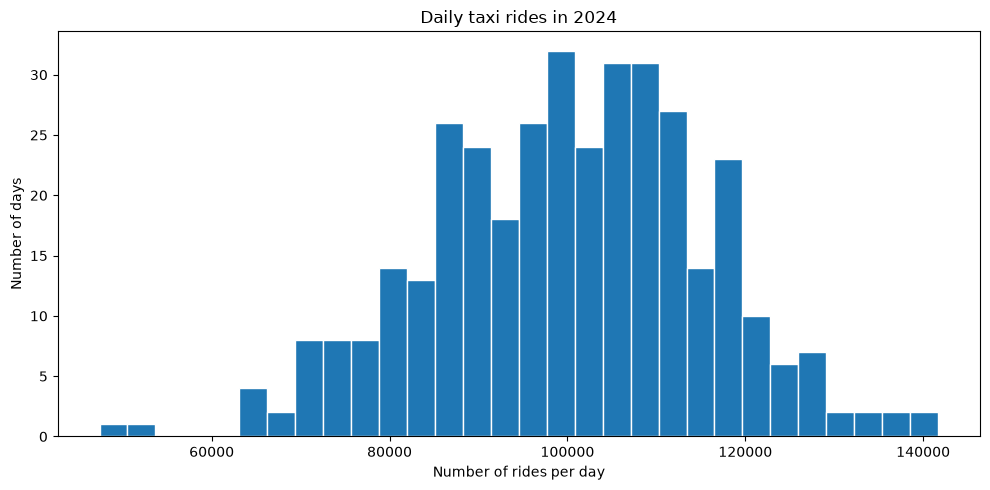

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(daily["total_rides"].to_numpy(), bins=30, edgecolor="white")
ax.set(
    title="Daily taxi rides in 2024",
    xlabel="Number of rides per day",
    ylabel="Number of days",
)
plt.tight_layout()
plt.show()

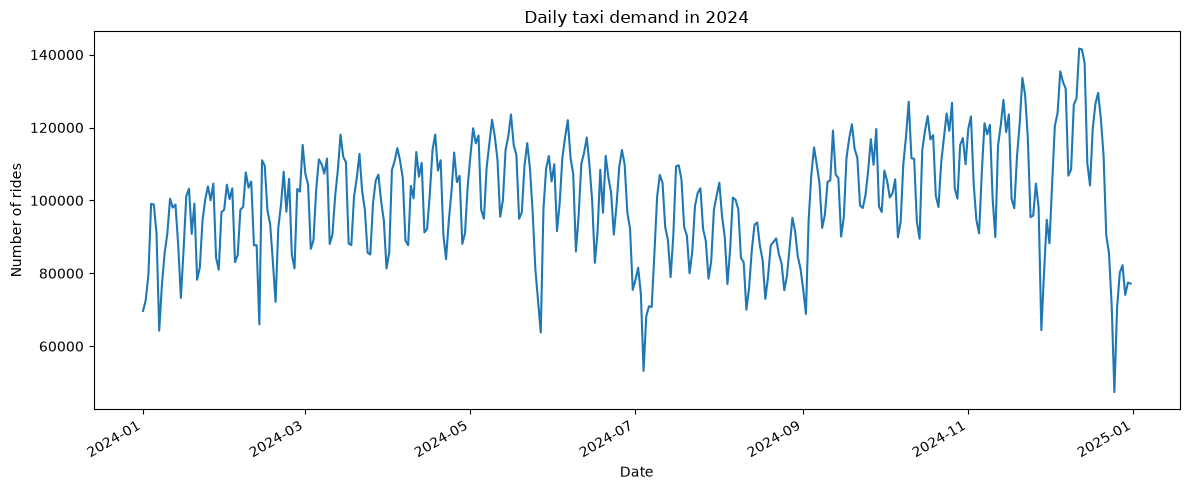

In [22]:
plot_data = daily.sort("date").to_pandas()
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(plot_data["date"], plot_data["total_rides"])
ax.set(title="Daily taxi demand in 2024", xlabel="Date", ylabel="Number of rides")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()